# Should a new market learn from other markets?
## Cross-market next-destination recommendation on the Booking.com Multi-Destination Trips dataset

**Business Intelligence — Individual Term Project (Fall 2026)**

**Business decision.** When a travel platform recommends the *next city* of a multi-city trip, should the
model for travellers from one country be trained on (a) that country's bookings only, (b) all countries'
bookings pooled together, or (c) a mix? This matters most when a platform enters a market with little data.

**Research question.** For which booker-country markets does pooling other markets' data improve
next-destination recommendations, and does that depend on market size, on how distinctive the market's
travel behaviour is, or both?

**Hypotheses.**
- **H1 (size):** markets with little training data gain more from pooling.
- **H2 (distinctiveness):** markets whose destinations differ strongly from other markets gain less from
  pooling, and can be hurt by it.

Run top to bottom. Runtime is about 4 minutes on a laptop. All numbers in the report come from this notebook.

## 1. Setup and data loading

In [1]:
import os, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from recsys import (load, to_trips, validation_split, TransitionModel,
                    recommend_blend, recommend_popularity, score,
                    bootstrap_ci, paired_bootstrap_diff, K)

os.makedirs('figures', exist_ok=True); os.makedirs('results', exist_ok=True)
pd.set_option('display.width', 140)

# Colours: fixed per model everywhere (validated categorical slots 1-3 + neutral grey)
COL = {'Own market': '#2a78d6', 'Pooled': '#eb6834', 'Blend': '#1baf7a', 'Popularity': '#9b9a95'}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
                     'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})

t0 = time.time()
train_bookings, test = load('data_repo')        # test = one row per test trip, last city hidden
train = to_trips(train_bookings)                # one row per training trip
fit, val = validation_split(train, frac=0.1)    # validation = last city of 10% of TRAIN trips
print(f'train bookings {len(train_bookings):,} | train trips {len(train):,} | '
      f'test trips {len(test):,} | validation trips {len(val):,}')

train bookings 1,166,835 | train trips 217,686 | test trips 70,662 | validation trips 21,936


## 2. Data audit

The dataset (Goldenberg & Levin, SIGIR 2021) contains 1,166,835 anonymised hotel reservations
(Dec 2015 – Feb 2017). Countries and cities are replaced by codes or fictional names, so
**"Gondal" is a market label, not a real country**. `booker_country` is where the reservation was made
from, not the traveller's nationality.

The official test set hides the last city of each of 70,662 trips; `ground_truth.csv` holds the answers.
We use the official split as-is. Model choices (the blend weight) are tuned only on a validation split
taken from the training data, never on the test set.

In [2]:
def js_divergence(p, q):
    """Jensen-Shannon divergence (base 2, range 0-1) between two {item: probability} dicts."""
    keys = list(set(p) | set(q))
    P = np.array([p.get(k, 0.0) for k in keys]); Q = np.array([q.get(k, 0.0) for k in keys])
    M = (P + Q) / 2
    kl = lambda a, b: float(np.sum(a[a > 0] * np.log2(a[a > 0] / b[a > 0])))
    return 0.5 * kl(P, M) + 0.5 * kl(Q, M)

tb = train_bookings
countries = train.booker_country.value_counts().index.tolist()
prof = []
for c in countries:
    mine, rest = tb[tb.booker_country == c], tb[tb.booker_country != c]
    prof.append({
        'market': c,
        'train trips': (train.booker_country == c).sum(),
        'share of trips': (train.booker_country == c).mean(),
        'test trips': (test.booker_country == c).sum(),
        'domestic bookings': (mine.hotel_country == c).mean(),
        'top destinations': ', '.join(mine.hotel_country.value_counts().head(3).index),
        'distinctiveness (JS)': js_divergence(mine.city_id.value_counts(normalize=True).to_dict(),
                                              rest.city_id.value_counts(normalize=True).to_dict()),
    })
profile = pd.DataFrame(prof).set_index('market')
profile.to_csv('results/market_profile.csv')
lengths = train.seq.str.len()
print(f'cities: {tb.city_id.nunique():,} | hotel countries: {tb.hotel_country.nunique()} | '
      f'bookings per trip: median {lengths.median():.0f}, mean {lengths.mean():.2f}')
profile.style.format({'share of trips': '{:.1%}', 'domestic bookings': '{:.1%}',
                      'distinctiveness (JS)': '{:.3f}', 'train trips': '{:,}', 'test trips': '{:,}'})

cities: 39,901 | hotel countries: 195 | bookings per trip: median 5, mean 5.36


,train trips,share of trips,test trips,domestic bookings,top destinations,distinctiveness (JS)
market,,,,,,
Gondal,"100,592",46.2%,"32,630",14.5%,"Gondal, Fook Island, Cobra Island",0.240
The Devilfire Empire,"51,694",23.7%,"16,882",1.4%,"Cobra Island, Borginia, Fook Island",0.368
Elbonia,"43,490",20.0%,"13,843",9.8%,"Cobra Island, Fook Island, Elbonia",0.176
Tcherkistan,"16,291",7.5%,"5,459",4.3%,"Drusselstein, Aldovia, Oceania",0.579
Bartovia,"5,619",2.6%,"1,848",13.6%,"Bartovia, Fook Island, Cobra Island",0.333


**Distinctiveness** is the Jensen-Shannon divergence between the cities a market books and the cities all
other markets book (0 = identical, 1 = no overlap). Tcherkistan is the most distinctive market: its top
destinations (Drusselstein, Aldovia) are not top destinations for anyone else.

## 3. Models

All models are simple counting models, so any accuracy difference comes from **which data** the model
learns from, not from model complexity.

| Model | Training data | How it ranks the next city |
|---|---|---|
| **Popularity** (baseline) | all markets | the 4 most-booked cities overall |
| **Own market** | this market only | cities that most often followed the trip's last city; fallback: popular cities in the same hotel country, then overall |
| **Pooled** | all markets | same as Own market |
| **Blend** | both | `α · P_own(next ∣ last) + (1−α) · P_pooled(next ∣ last)`, α chosen per market on validation data |

The trip's current city *can* be recommended again: about 9% of consecutive bookings (and 9.8% of test answers)
are a second stay in the same city. Each test trip has exactly one correct next city, so

- **Recall@4** = share of trips whose true next city is in the top 4 (= the challenge's accuracy@4)
- **NDCG@4** also rewards ranking it higher: 1/log₂(rank+1) if found at position `rank`, else 0
- **Item coverage** = distinct recommended cities ÷ cities in the training catalogue

## 4. Experiment 1 — every market, full data

In [3]:
ALPHAS = np.round(np.arange(0, 1.01, 0.1), 1)
pool_fit = TransitionModel().fit(fit)       # for tuning α
pooled   = TransitionModel().fit(train)     # final pooled model
catalog  = len(pooled.pop)

def run(own, pool, alpha, T):
    return [recommend_blend(own, pool, alpha, s, l) for s, l in zip(T.seq, T.last_country)]

rows, per_trip, own_models = [], {}, {}
for c in countries:
    # tune α on validation trips of this market only
    own_fit = TransitionModel().fit(fit[fit.booker_country == c])
    V = val[val.booker_country == c]
    val_recall = {a: score(run(own_fit, pool_fit, a, V), V.target.values)[0].mean() for a in ALPHAS}
    alpha = max(val_recall, key=val_recall.get)

    own = TransitionModel().fit(train[train.booker_country == c]); own_models[c] = own
    T = test[test.booker_country == c]
    recs = {'Popularity': [recommend_popularity(pooled, s) for s in T.seq],
            'Own market': run(own, pooled, 1.0, T),
            'Pooled':     run(own, pooled, 0.0, T),
            'Blend':      run(own, pooled, alpha, T)}
    for m, r in recs.items():
        rec, ndcg = score(r, T.target.values)
        per_trip[(c, m)] = (rec, ndcg)
        lo, hi = bootstrap_ci(rec)
        rows.append({'market': c, 'model': m, 'alpha': alpha, 'Recall@4': rec.mean(),
                     'CI low': lo, 'CI high': hi, 'NDCG@4': ndcg.mean(),
                     'coverage': len({x for rr in r for x in rr}) / catalog, 'n test': len(T)})
res1 = pd.DataFrame(rows); res1.to_csv('results/exp1_by_market.csv', index=False)

# overall (all test trips)
overall = {}
for m in ['Popularity', 'Own market', 'Pooled', 'Blend']:
    rec = np.concatenate([per_trip[(c, m)][0] for c in countries])
    nd  = np.concatenate([per_trip[(c, m)][1] for c in countries])
    overall[m] = (rec.mean(), nd.mean())
print('All test trips:', {m: f'R@4 {r:.4f} / NDCG@4 {n:.4f}' for m, (r, n) in overall.items()})
pd.DataFrame(overall, index=['Recall@4', 'NDCG@4']).T.to_csv('results/exp1_overall.csv')
print(f'elapsed {time.time()-t0:.0f}s')
res1.pivot(index='market', columns='model', values='Recall@4').loc[countries].round(4)

All test trips: {'Popularity': 'R@4 0.0527 / NDCG@4 0.0354', 'Own market': 'R@4 0.4612 / NDCG@4 0.3570', 'Pooled': 'R@4 0.4614 / NDCG@4 0.3562', 'Blend': 'R@4 0.4691 / NDCG@4 0.3623'}
elapsed 63s


model,Blend,Own market,Pooled,Popularity
market,,,,
Gondal,0.4024,0.3956,0.4032,0.0407
The Devilfire Empire,0.6272,0.6277,0.6036,0.0961
Elbonia,0.3732,0.3511,0.3717,0.0344
Tcherkistan,0.6716,0.6734,0.6419,0.0429
Bartovia,0.3231,0.2955,0.3274,0.0352


In [4]:
# Is the Own-vs-Pooled difference real? Paired bootstrap over the SAME test trips.
diff = []
for c in countries:
    d, lo, hi = paired_bootstrap_diff(per_trip[(c, 'Pooled')][0], per_trip[(c, 'Own market')][0])
    diff.append({'market': c, 'train trips': profile.loc[c, 'train trips'],
                 'distinctiveness (JS)': profile.loc[c, 'distinctiveness (JS)'],
                 'pooling gain (Pooled − Own), pp': 100 * d, '95% CI low': 100 * lo, '95% CI high': 100 * hi,
                 'chosen α': res1[(res1.market == c)].alpha.iloc[0]})
gain = pd.DataFrame(diff).set_index('market'); gain.to_csv('results/exp1_pooling_gain.csv')
gain.round(3)

,train trips,distinctiveness (JS),"pooling gain (Pooled − Own), pp",95% CI low,95% CI high,chosen α
market,,,,,,
Gondal,100592,0.240,0.754,0.518,1.017,0.4
The Devilfire Empire,51694,0.368,-2.405,-2.802,-1.984,0.6
Elbonia,43490,0.176,2.066,1.568,2.644,0.3
Tcherkistan,16291,0.579,-3.151,-3.938,-2.418,0.9
Bartovia,5619,0.333,3.193,1.353,5.088,0.4


In [5]:
# NDCG and coverage table
res1.pivot(index='market', columns='model', values=['NDCG@4', 'coverage']).loc[countries].round(4)

NDCG@4                               coverage                              
model                  Blend Own market  Pooled Popularity    Blend Own market  Pooled Popularity
market                                                                                           
Gondal                0.3038     0.2980  0.3042     0.0279   0.2163     0.2027  0.2128     0.0001
The Devilfire Empire  0.4877     0.4923  0.4721     0.0616   0.0736     0.0577  0.0759     0.0001
Elbonia               0.2827     0.2660  0.2817     0.0256   0.1685     0.1574  0.1603     0.0001
Tcherkistan           0.5670     0.5696  0.5355     0.0268   0.0323     0.0219  0.0341     0.0001
Bartovia              0.2425     0.2172  0.2459     0.0296   0.0508     0.0367  0.0464     0.0001

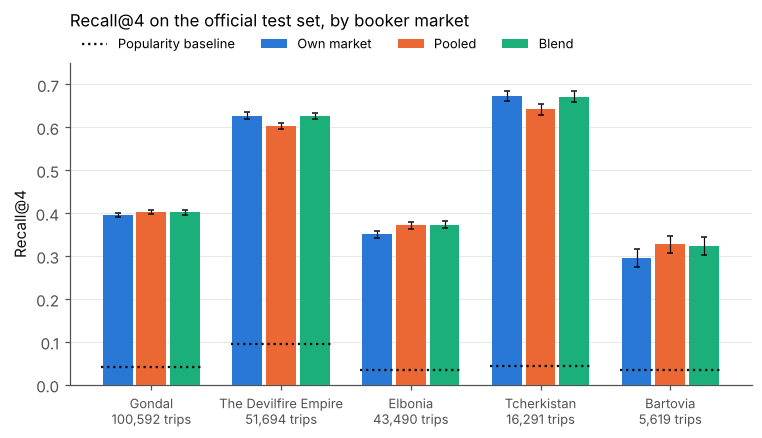

In [6]:
# Figure 1 — Recall@4 by market and model (error bars = 95% bootstrap CI)
models = ['Own market', 'Pooled', 'Blend']
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(countries)); w = 0.26
for i, m in enumerate(models):
    d = res1[res1.model == m].set_index('market').loc[countries]
    ax.bar(x + (i - 1) * w, d['Recall@4'], w - 0.03, color=COL[m], label=m, zorder=3)
    ax.errorbar(x + (i - 1) * w, d['Recall@4'],
                yerr=[d['Recall@4'] - d['CI low'], d['CI high'] - d['Recall@4']],
                fmt='none', ecolor='#0b0b0b', elinewidth=0.8, capsize=2, zorder=4)
pop = res1[res1.model == 'Popularity'].set_index('market').loc[countries, 'Recall@4']
ax.hlines(pop, x - 1.5 * w, x + 1.5 * w, colors='#0b0b0b', linestyles=':', lw=1.5, zorder=5,
          label='Popularity baseline')
labels = [f"{c}\n{profile.loc[c, 'train trips']:,} trips" for c in countries]
ax.set_xticks(x, labels, fontsize=8.5); ax.set_ylabel('Recall@4'); ax.set_ylim(0, 0.75)
ax.grid(axis='x', visible=False)
ax.set_title('Recall@4 on the official test set, by booker market', loc='left', fontsize=11, pad=24)
ax.legend(ncol=4, frameon=False, fontsize=8.5, loc='lower left', bbox_to_anchor=(0, 1.0))
fig.savefig('figures/fig1_recall_by_market.png'); plt.show()

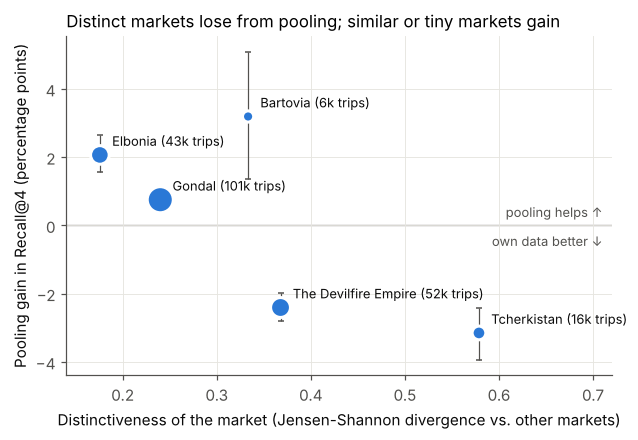

In [7]:
# Figure 2 — what predicts the pooling gain? size vs distinctiveness
fig, ax = plt.subplots(figsize=(6.4, 4))
g = gain.copy()
ax.axhline(0, color='#52514e', lw=0.8, zorder=1)
ax.errorbar(g['distinctiveness (JS)'], g['pooling gain (Pooled − Own), pp'],
            yerr=[g['pooling gain (Pooled − Own), pp'] - g['95% CI low'],
                  g['95% CI high'] - g['pooling gain (Pooled − Own), pp']],
            fmt='none', ecolor='#52514e', elinewidth=0.8, capsize=2, zorder=2)
ax.scatter(g['distinctiveness (JS)'], g['pooling gain (Pooled − Own), pp'],
           s=40 + g['train trips'] / 400, color='#2a78d6', edgecolor='white', linewidth=2, zorder=3)
for c, r in g.iterrows():
    ax.annotate(f"{c} ({r['train trips']/1000:.0f}k trips)",
                (r['distinctiveness (JS)'], r['pooling gain (Pooled − Own), pp']),
                xytext=(8, 6), textcoords='offset points', fontsize=8.5, color='#0b0b0b')
ax.set_xlabel('Distinctiveness of the market (Jensen-Shannon divergence vs. other markets)')
ax.set_ylabel('Pooling gain in Recall@4 (percentage points)')
ax.text(0.71, 0.25, 'pooling helps ↑', color='#52514e', fontsize=8.5, ha='right')
ax.text(0.71, -0.6, 'own data better ↓', color='#52514e', fontsize=8.5, ha='right')
ax.set_xlim(0.14, 0.72)
ax.set_title('Distinct markets lose from pooling; similar or tiny markets gain', loc='left', fontsize=11)
fig.savefig('figures/fig2_gain_vs_distinctiveness.png'); plt.show()

## 5. Experiment 2 — simulated market entry

Experiment 1 mixes size and distinctiveness, because each market has a different size. To separate them
we **simulate entering a market**: keep all other markets' data, but give the target market only N of its
own training trips (N = 250 … all). The test trips stay the same. We do this for:

- **Tcherkistan**, the most distinctive market (JS 0.58)
- **Elbonia**, the least distinctive market (JS 0.18)

If H1 alone were true, pooling would win at small N for both markets. Two random samples are drawn for
each N below 10,000; the plot shows their mean.

In [8]:
ALPHAS2 = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
rows2 = []
for c, Ns in [('Tcherkistan', [250, 1000, 4000, 16291]), ('Elbonia', [250, 1000, 4000, 16000, 43490])]:
    T, V = test[test.booker_country == c], val[val.booker_country == c]
    mine, fmine = train[train.booker_country == c], fit[fit.booker_country == c]
    for N in Ns:
        for seed in ([0, 1] if N < 10000 else [0]):
            sub  = mine.sample(n=min(N, len(mine)), random_state=seed)
            fsub = fmine.sample(n=min(int(N * 0.9), len(fmine)), random_state=seed)
            o_f = TransitionModel().fit(fsub)
            p_f = TransitionModel().fit(pd.concat([fit[fit.booker_country != c], fsub]))
            vr = {a: score(run(o_f, p_f, a, V), V.target.values)[0].mean() for a in ALPHAS2}
            alpha = max(vr, key=vr.get)
            o = TransitionModel().fit(sub)
            p = TransitionModel().fit(pd.concat([train[train.booker_country != c], sub]))
            for m, a in [('Own market', 1.0), ('Pooled', 0.0), ('Blend', alpha)]:
                rows2.append({'market': c, 'N own trips': N, 'seed': seed, 'model': m, 'alpha': alpha,
                              'Recall@4': score(run(o, p, a, T), T.target.values)[0].mean()})
res2 = pd.DataFrame(rows2); res2.to_csv('results/exp2_market_entry.csv', index=False)
print(f'elapsed {time.time()-t0:.0f}s')
res2.groupby(['market', 'N own trips', 'model'])['Recall@4'].mean().unstack().round(4)

elapsed 146s


model                     Blend  Own market  Pooled
market      N own trips                            
Elbonia     250          0.3551      0.1855  0.3551
            1000         0.3560      0.2395  0.3560
            4000         0.3573      0.2781  0.3573
            16000        0.3595      0.3234  0.3630
            43490        0.3728      0.3491  0.3722
Tcherkistan 250          0.5895      0.5588  0.5705
            1000         0.6139      0.6065  0.5949
            4000         0.6454      0.6503  0.6112
            16291        0.6705      0.6730  0.6417

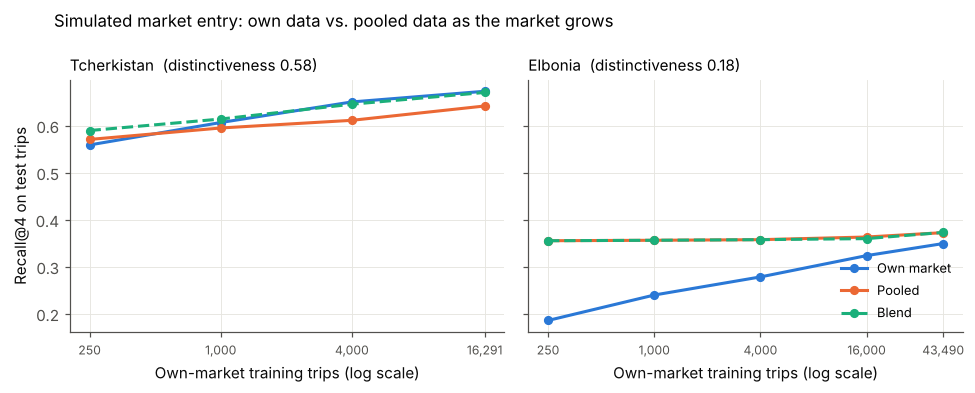

In [9]:
# Figure 3 — learning curves
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, c in zip(axes, ['Tcherkistan', 'Elbonia']):
    d = res2[res2.market == c].groupby(['N own trips', 'model'])['Recall@4'].mean().unstack()
    for m, ls in [('Own market', '-'), ('Pooled', '-'), ('Blend', '--')]:
        ax.plot(d.index, d[m], color=COL[m], lw=2, ls=ls, marker='o', ms=5, label=m)
    ax.set_xscale('log'); ax.set_xlabel('Own-market training trips (log scale)')
    ax.set_xticks(d.index, [f'{n:,}' for n in d.index], fontsize=8); ax.minorticks_off()
    js = profile.loc[c, 'distinctiveness (JS)']
    ax.set_title(f'{c}  (distinctiveness {js:.2f})', loc='left', fontsize=10)
axes[0].set_ylabel('Recall@4 on test trips')
axes[1].legend(frameon=False, fontsize=8.5, loc='lower right')
fig.suptitle('Simulated market entry: own data vs. pooled data as the market grows',
             x=0.06, ha='left', fontsize=11)
fig.tight_layout(); fig.savefig('figures/fig3_market_entry.png'); plt.show()

## 6. Failure analysis

Where and why does each approach fail?

1. **Own model, cold start.** If the trip's last city never appears in the market's own training trips,
   the Own model has no transitions and can only fall back to popular cities.
2. **Pooled model, crowding out.** When a city is visited by many travellers from *other* markets, their
   habits dominate the pooled counts, even if this market's travellers go somewhere else next.
3. **A hypothesis that did not hold:** we expected domestic trips (destination in the booker's own country)
   to explain the pooling losses. We test it below.

In [10]:
fa = []
for c in countries:
    T = test[test.booker_country == c].reset_index(drop=True)
    own = own_models[c]
    last = T.seq.str[-1]
    seen = last.map(lambda a: a in own.trans and len(own.trans[a]) > 0)
    # market's share of all transitions leaving the last city (in pooled data)
    share = [sum(own.trans[a].values()) / max(1, sum(pooled.trans[a].values())) if a in pooled.trans else np.nan
             for a in last]
    share = pd.Series(share)
    dom = (T.target_country == c)
    r_own, r_pool = per_trip[(c, 'Own market')][0], per_trip[(c, 'Pooled')][0]
    def seg(name, mask):
        mask = np.asarray(mask, dtype=bool)
        if mask.sum() == 0: return
        fa.append({'market': c, 'segment': name, 'trips': int(mask.sum()), 'share of trips': mask.mean(),
                   'Own R@4': r_own[mask].mean(), 'Pooled R@4': r_pool[mask].mean(),
                   'gain pp': 100 * (r_pool[mask].mean() - r_own[mask].mean())})
    seg('last city unseen in own data', ~seen)
    seg('last city seen in own data', seen)
    seg('market makes <25% of traffic from last city', share < 0.25)
    seg('market makes 25-75% of traffic', (share >= 0.25) & (share <= 0.75))
    seg('market makes >75% of traffic', share > 0.75)
    seg('domestic next city', dom)
    seg('international next city', ~dom)
failures = pd.DataFrame(fa); failures.to_csv('results/failure_analysis.csv', index=False)
failures.set_index(['market', 'segment']).round(3)

trips  share of trips  Own R@4  Pooled R@4  gain pp
market               segment                                                                                         
Gondal               last city unseen in own data                   464           0.014    0.188       0.185   -0.216
                     last city seen in own data                   32166           0.986    0.399       0.406    0.768
                     market makes <25% of traffic from last city   2524           0.077    0.384       0.399    1.506
                     market makes 25-75% of traffic               20394           0.625    0.423       0.431    0.760
                     market makes >75% of traffic                  9615           0.295    0.342       0.348    0.562
                     domestic next city                            5822           0.178    0.191       0.191    0.017
                     international next city                      26808           0.822    0.440       0.449    0.914
The Devilfire Empire last city unseen in own data                   251           0.015    0.299       0.219   -7.968
                     last city seen in own data                   16631           0.985    0.633       0.609   -2.321
                     market makes <25% of traffic from last city   3048           0.181    0.538       0.440   -9.843
                     market makes 25-75% of traffic               10128           0.600    0.620       0.611   -0.938
                     market makes >75% of traffic                  3692           0.219    0.725       0.722   -0.325
                     domestic next city                             283           0.017    0.657       0.675    1.767
                     international next city                      16599           0.983    0.627       0.602   -2.476
Elbonia              last city unseen in own data                   537           0.039    0.164       0.171    0.745
                     last city seen in own data                   13306           0.961    0.359       0.380    2.119
                     market makes <25% of traffic from last city   7049           0.509    0.366       0.390    2.383
                     market makes 25-75% of traffic                5932           0.429    0.344       0.364    2.006
                     market makes >75% of traffic                   793           0.057    0.293       0.289   -0.378
                     domestic next city                            1697           0.123    0.176       0.176   -0.059
                     international next city                      12146           0.877    0.376       0.399    2.363
Tcherkistan          last city unseen in own data                   152           0.028    0.362       0.276   -8.553
                     last city seen in own data                    5307           0.972    0.682       0.652   -2.996
                     market makes <25% of traffic from last city   2034           0.373    0.543       0.472   -7.080
                     market makes 25-75% of traffic                1524           0.279    0.621       0.602   -1.903
                     market makes >75% of traffic                  1896           0.347    0.856       0.857    0.053
                     domestic next city                             281           0.051    0.712       0.708   -0.356
                     international next city                       5178           0.949    0.671       0.638   -3.302
Bartovia             last city unseen in own data                   275           0.149    0.196       0.189   -0.727
                     last city seen in own data                    1573           0.851    0.313       0.352    3.878
                     market makes <25% of traffic from last city   1574           0.852    0.297       0.335    3.748
                     market makes 25-75% of traffic                 241           0.130    0.320       0.320    0.000
                     market makes >75% of traffic     

In [11]:
# Concrete example: one city where pooling crowds out Tcherkistan's own pattern
c = 'Tcherkistan'; own = own_models[c]
T = test[test.booker_country == c]
lastc = T.seq.str[-1].value_counts()
for a in lastc.index[:40]:
    o_top = [b for b, _ in own.trans[a].most_common(4)]
    p_top = [b for b, _ in pooled.trans[a].most_common(4)]
    if len(set(o_top) & set(p_top)) <= 1 and sum(own.trans[a].values()) > 50:
        tot_o, tot_p = sum(own.trans[a].values()), sum(pooled.trans[a].values())
        print(f'Last city {a}: {lastc[a]} Tcherkistan test trips end here; '
              f'Tcherkistan makes {tot_o/tot_p:.0%} of the {tot_p:,} recorded departures from it.')
        print('  Tcherkistan travellers next go to:', own.trans[a].most_common(4))
        print('  Pooled top-4 recommendation:      ', pooled.trans[a].most_common(4))
        break

Last city 55763: 47 Tcherkistan test trips end here; Tcherkistan makes 17% of the 3,619 recorded departures from it.
  Tcherkistan travellers next go to: [(55763, 280), (36063, 51), (9698, 34), (45188, 14)]
  Pooled top-4 recommendation:       [(55763, 1267), (61320, 235), (9161, 139), (63284, 138)]


In [12]:
# Blend: did validation pick the right side?
chk = gain[['chosen α', 'pooling gain (Pooled − Own), pp']].copy()
chk['validation picked'] = np.where(chk['chosen α'] >= 0.5, 'mostly own', 'mostly pooled')
chk['test winner'] = np.where(chk['pooling gain (Pooled − Own), pp'] > 0, 'pooled', 'own')
chk

,chosen α,"pooling gain (Pooled − Own), pp",validation picked,test winner
market,,,,
Gondal,0.4,0.753907,mostly pooled,pooled
The Devilfire Empire,0.6,-2.404928,mostly own,own
Elbonia,0.3,2.066026,mostly pooled,pooled
Tcherkistan,0.9,-3.150760,mostly own,own
Bartovia,0.4,3.192641,mostly pooled,pooled


## 7. Summary of findings

(Numbers are printed above; the report discusses them.)

1. **Transition models beat the popularity baseline about 9×** (Recall@4 ≈ 0.46 vs 0.05 over all test trips).
2. **Size alone does not decide.** Pooling helped the smallest market (Bartovia) and the two least distinctive
   markets (Gondal, Elbonia), but **hurt** the two most distinctive markets (Tcherkistan, The Devilfire Empire).
   All five differences have 95% confidence intervals that exclude zero.
3. **The market-entry simulation separates the two factors.** For distinctive Tcherkistan, pooled data won only
   at the very start (250 trips); from about 1,000 own trips, own data was better. For similar Elbonia, pooled
   data won at every size. The blend, with α chosen on validation data, was best or close to best at every size.
4. **Failure modes:** the pooled model fails where other markets dominate the traffic out of a city
   (crowding out, up to −10 pp); the own model fails where it has too little data (Bartovia). Domestic travel
   did not explain the losses.
5. **Business implication:** decide per market, not with one global rule. Start a new market on pooled or
   blended data, measure how distinctive its demand is, and let validation data choose the mix as the
   market grows.

In [13]:
print(f'Total runtime: {time.time()-t0:.0f}s')

Total runtime: 147s
